# 02 · Statistics problems in trading: estimation, stationarity and edge

**Original lecture:** [Quant Guild #3, *How to Make & Lose Money Trading*](https://github.com/romanmichaelpaolucci/Quant-Guild-Library/tree/main/2025%20Video%20Lectures/3.%20How%20to%20Make%20%26%20Lose%20Money%20Trading) · [video](https://youtu.be/WP9fb7AMFsI)

> **Starter notebook.** You write the code. Each task has an empty cell marked `# TODO`, followed by a **checkpoint** cell that prints ✅, ❌ with a hint, or ⏳ (not done yet). You can *Run All* at any time to see where you stand.
>
> The rules: **predict before you run**, **type it, don't paste it**, and if you're stuck for more than 15 minutes, ask Claude for a *hint*.

**The question.** A trader shows you 7 trades: 4 winners and 3 losers, positive average P/L. Do they have an edge? By the end you'll be able to answer with numbers, and you'll see why the honest answer is usually *we can't tell yet*.

| Part | Idea | Time |
|---|---|---|
| 1 | **Estimation:** how much can a sample of trades tell you? | Day 1–2 |
| 2 | **Stationarity:** what if the thing you estimate keeps moving? | Day 2 |
| 3 | **Edge:** the law of total expectation, breakeven win rates, equity curves | Day 3 |
| 4 | **Real data:** SPY's daily edge with a bootstrap confidence interval | Day 4 |
| 5 | **Your extension** + takeaways | Day 5 |

**Fill in when finished:** *What's new compared with the original* (one row per idea you added):

| New compared with the original | Where |
|---|---|
| *(e.g. bootstrap CI on a real edge)* | Part 4 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from qgs import load_prices, set_style
from qgs.checks import p02 as check

set_style()
rng = np.random.default_rng(42)

## Part 1 · Parameter estimation

Every trading statistic is an **estimate**: win rate, average win, Sharpe. Start with the simplest one. A coin lands heads with unknown probability $p$. After $n$ flips the natural estimate is

$$\hat p = \frac{\#\text{heads}}{n}, \qquad \mathbb E[\hat p] = p, \qquad \operatorname{sd}(\hat p) = \sqrt{\frac{p(1-p)}{n}}.$$

That last formula is the **standard error**. It shrinks like $1/\sqrt n$: to halve your uncertainty you need **four times** the data.

### Task 1.1
Write `estimate_p(n_flips, p, rng)`, which flips a coin with heads-probability `p` `n_flips` times and returns the fraction of heads.

*Useful:* `rng.random(n) < p` gives an array of True/False; `rng.binomial(n, p)` counts successes directly. Either works.

In [2]:
def estimate_p(n_flips, p, rng):
    p_est = rng.binomial(n_flips, p) / n_flips
    return p_est

In [3]:
check.task1_1(estimate_p)

✅ Task 1.1 estimate_p: unbiased estimator of p


True

### Task 1.2
**Predict first** (write your guess here): with $n = 10$ flips of a fair coin, what is the standard deviation of $\hat p$? ➜ *my prediction: 0.158*

Now simulate 10,000 experiments of 10 flips each, store the estimates in `p_hats_10`, and plot a histogram. Mark the true $p = 0.5$ with a vertical line.

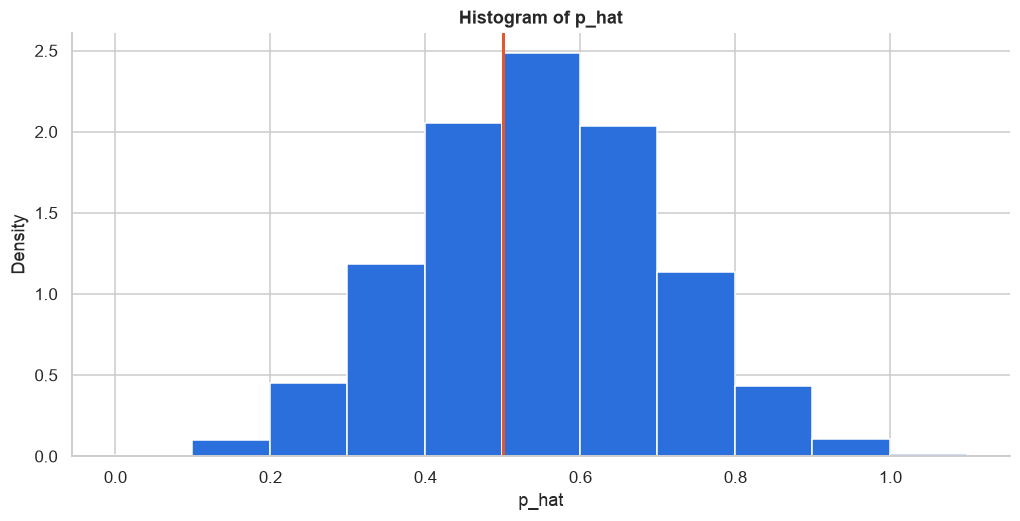

In [4]:
p_hats_10 = np.array([estimate_p(10, 0.5, rng) for run in range(10000)])
plt.hist(p_hats_10, bins=np.arange(-0.001, 1.10001, 0.1), density=True)
plt.axvline(0.5, color="C1", lw=2)
plt.xlabel("p_hat"); plt.ylabel("Density"); plt.title("Histogram of p_hat")
plt.show()

In [5]:
check.task1_2(p_hats_10)

✅ Task 1.2 sampling distribution: sd = 0.159 vs theory 0.158: 10 trades tell you almost nothing


True

### Task 1.3
How does the error shrink with more data? For each `n` in `ns`, simulate 2,000 estimates and store their standard deviation in `se_empirical` (an array with one value per `n`). Plot it against the theoretical $\sqrt{0.25/n}$ on **log-log** axes (`ax.loglog`). What slope do you see, and why?

Then answer with algebra: how many trades do you need for a 95% confidence interval of $\pm 2\%$ around a 50% win rate? Store it in `n_needed`.

2400.9999999999927


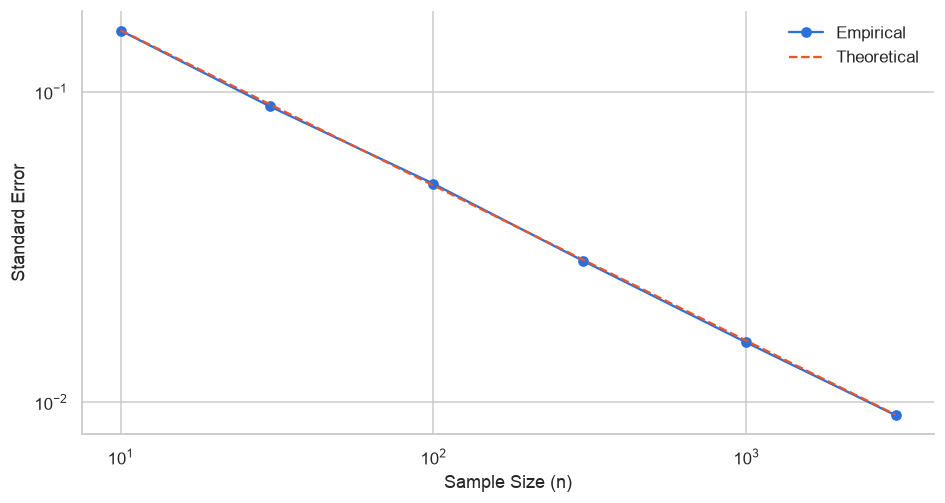

In [6]:
ns = [10, 30, 100, 300, 1000, 3000] #list of sample sizes
se_empirical = [np.std([estimate_p(n, 0.5, rng) for sim in range(2000)]) for n in ns]

plt.figure(figsize=(10, 5))
ax = plt.gca()
ax.loglog(ns, se_empirical, 'o-', label='Empirical')
ax.loglog(ns, np.sqrt(0.25/np.array(ns)), '--', label='Theoretical')
ax.set_xlabel('Sample Size (n)')
ax.set_ylabel('Standard Error')
ax.legend()
ax.grid(True)

#solve theoretical number of trade to get an accurate bound around 50% win rate
from scipy.optimize import fsolve

def equation(n):
    return 1.96 * np.sqrt(0.25 / n) - 0.02
n_needed = fsolve(equation, 0.5)[0]
print(n_needed)

In [7]:
check.task1_3(se_empirical, n_needed)

✅ Task 1.3 standard error vs n: you need ~2,401 trades to pin a 50% win rate to ±2%


True

✍️ **Interpret (2–3 sentences):** what does Task 1.3 imply for a trader who judges a new strategy after 30 trades?

*Your answer: The standard error of his estimate is going to be huge, meaning the uncertainty around his actual win rate.*

## Part 2 · Stationarity

Part 1 assumed $p$ stays fixed. Markets don't do that. Now each experiment draws its **own** true probability,

$$p_{\text{true}} \sim \mathcal N(0.5,\ 0.1^2) \ \text{(clipped to [0, 1])},$$

and then flips $n$ times using it. Think of each experiment as a different market regime.

### Task 2.1
Write `estimate_p_nonstationary(n_flips, rng, p0=0.5, sd=0.1)` that returns a tuple `(p_hat, p_true)`. Reuse `estimate_p` from Task 1.1.

In [8]:
def estimate_p_nonstationary(n_flips, rng, p0=0.5, sd=0.1):
    p_true = np.clip(rng.normal(p0, sd), 0, 1)
    p_hat = estimate_p(n_flips, p_true, rng)
    return p_hat, p_true

In [9]:
check.task2_1(estimate_p_nonstationary)

✅ Task 2.1 non-stationary estimator: passed


True

### Task 2.2
Run 10,000 experiments with $n = 1000$ flips each. You're interested in the long-run average win rate, 0.5. Compute the standard deviation of $\hat p - 0.5$ and store it in `sd_err_vs_half_1000`.

**Predict first:** in Part 1, 1,000 flips gave an error of about 0.016. What will you get now? ➜ *my prediction:*
I ll say 0.03 because the moving target will add more variance to the estimate and the standard deviation of the normal draw is 0.1, so the sum is roughly 0.1 + 0.016 = 0.116, but since we are looking at the standard deviation of the error from 0.5, it will be less than that, so I predict around 0.03.
Then explain it with the **law of total variance**: the law of total variance says that the variance of an estimator can be decomposed in 2 parts: the variance of the conditional expectation and the expectation of the conditional variance. In this case, the variance of the conditional expectation (conditioning on p = 0.5 ) is 0.1**2 and the expectation of the conditional variance is 0.016**2, so the total variance is 0.1**2 + 0.016**2 = 0.010256, and the standard deviation is sqrt(0.010256) = 0.1013, which is around 0.1, so my prediction of 0.03 was too low.

$$\operatorname{Var}(\hat p) = \underbrace{\mathbb E\left[\operatorname{Var}(\hat p \mid p)\right]}_{\text{sampling noise}} + \underbrace{\operatorname{Var}\left(\mathbb E[\hat p \mid p]\right)}_{\text{moving target}} = \frac{\mathbb E[p(1-p)]}{n} + \operatorname{Var}(p).$$

Using $\mathbb E[p(1-p)] = 0.25 - \operatorname{Var}(p)$, compute the theoretical sd for $n = 10$ by hand (in code) and store it in `sd_theory_10`.

*Bonus:* plot the sd of $\hat p - 0.5$ against $n$ for both the stationary and non-stationary cases on one chart.

In [10]:
errors = [estimate_p_nonstationary(1000, rng)[0] - 0.5 for run in range(10000)]
errors_stationary = [estimate_p(1000, 0.5, rng) - 0.5 for run in range(10000)]
sd_err_vs_half_1000 = np.std(errors)
sd_theory_10 = np.sqrt((0.25 - 0.1**2)/10 + 0.1**2)

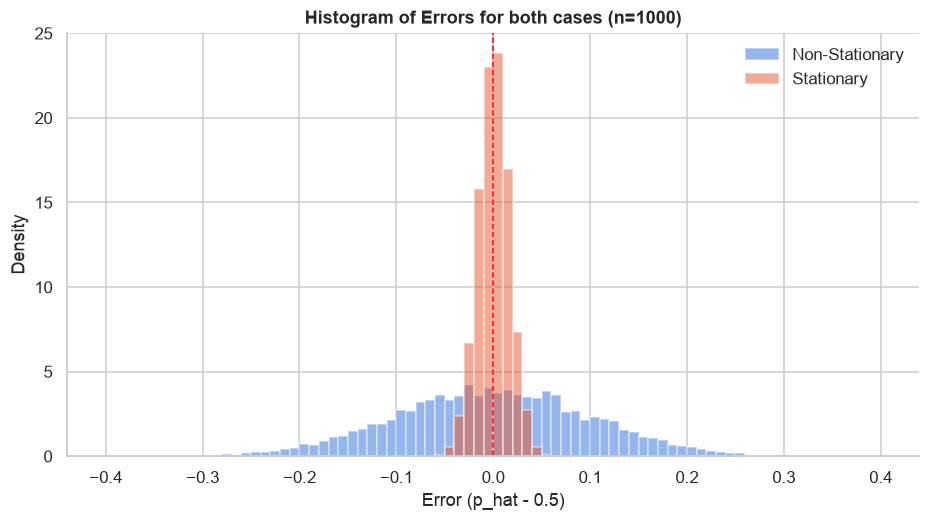

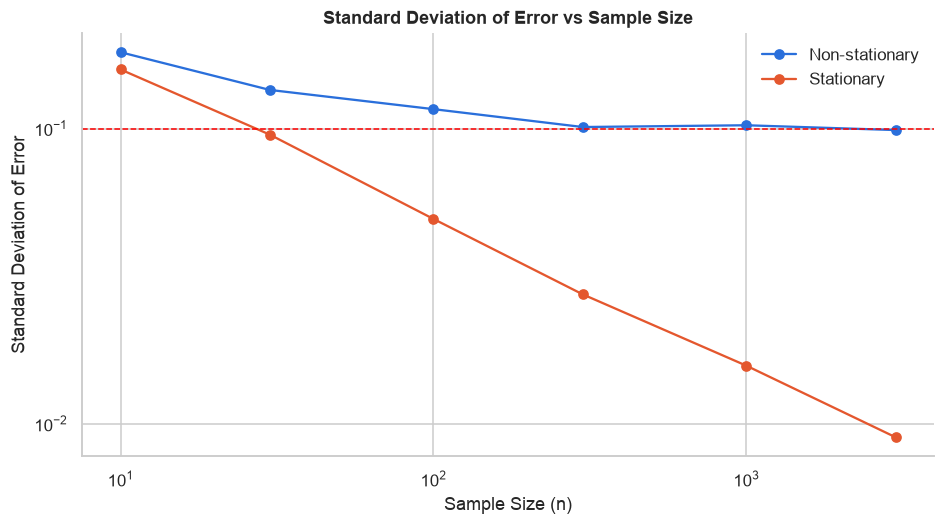

In [11]:
#Plotting
plt.figure(figsize=(10, 5))
bins = np.linspace(-0.4, 0.4, 81)
plt.hist(errors, alpha=0.5, bins=bins, density=True, label='Non-Stationary')
plt.hist(errors_stationary, alpha=0.5, bins=bins, density=True, label ='Stationary')
plt.legend()
plt.xlabel("Error (p_hat - 0.5)")
plt.ylabel("Density")
plt.title("Histogram of Errors for both cases (n=1000)")
plt.axvline(0, color='red', linestyle='dashed', linewidth=1)
plt.show()

#Second plot for sd vs n
ns = [10, 30, 100, 300, 1000, 3000]
sd_nonstationary = [np.std([estimate_p_nonstationary(n, rng)[0] - 0.5 for run in range(1000)]) for n in ns]
sd_stationary = [np.std([estimate_p(n, 0.5, rng) - 0.5 for run in range(1000)]) for n in ns]
plt.figure(figsize=(10, 5))
plt.loglog(ns, sd_nonstationary, 'o-', label='Non-stationary')
plt.loglog(ns, sd_stationary, 'o-', label='Stationary')
plt.axhline(0.1, color='red', linestyle='dashed', linewidth=1)
plt.xlabel('Sample Size (n)')
plt.ylabel('Standard Deviation of Error')
plt.legend()
plt.title('Standard Deviation of Error vs Sample Size')
plt.show()


In [12]:
check.task2_2(sd_err_vs_half_1000, sd_theory_10)

✅ Task 2.2 law of total variance: more data shrinks noise, not the uncertainty from a moving target


True

✍️ **Interpret:** why does collecting more data stop helping once the edge itself moves? What does that mean for backtests run over 20 years of data?

*Your answer:* For long backtests, the edge may have changed over time, so the results may not be representative of the current market conditions, due to market regime changes. The standard deviation of the estimate will not decrease as much as expected because the underlying probability is moving, which means that even with more data, the estimate may still be inaccurate, because the variance of the estimator now has the unconditional variance of the distribution as its effective floor, due to the law of total variance decomposition.

## Part 3 · What is an "edge"?

Let $S$ be a strategy's P/L per trade and $W$ the event "the trade wins". By the **law of total expectation**,

$$\mathbb E[S] = \underbrace{\mathbb E[S \mid W]}_{\text{avg win}}\,P(W) + \underbrace{\mathbb E[S \mid W^c]}_{\text{avg loss}}\,\big(1 - P(W)\big).$$

A high win rate means nothing on its own: what matters is win rate **and** payoff together.

### Task 3.1
Here are the lecture's 7 trades. Compute `p_win`, `avg_win`, `avg_loss` (a negative number), then `edge_total_expectation` from the formula above, and `mean_pl` as the plain average. They should agree.

In [13]:
trades = pd.DataFrame({"pl": [150, 120, 90, 100, -300, -100, -50]})

p_win = trades[trades['pl'] > 0].shape[0] / trades.shape[0]
avg_win = np.mean(trades[trades['pl'] > 0]['pl'])
avg_loss = np.mean(trades[trades['pl'] < 0]['pl'])
edge_total_expectation = p_win * avg_win + (1 - p_win) * avg_loss
mean_pl = np.mean(trades['pl'])

In [14]:
check.task3_1(p_win, avg_win, avg_loss, edge_total_expectation, mean_pl)

✅ Task 3.1 edge decomposition: edge = 1.43 per trade, same as the plain mean


True

### Task 3.2
Write two small functions:
- `edge(p_win, avg_win, avg_loss)`: expected P/L per trade.
- `breakeven_p(avg_win, avg_loss)`: the win rate at which the edge is exactly zero. Derive it on paper first.

Then plot `edge(p, 115, -150)` for `p` from 0 to 1 and mark the breakeven point.

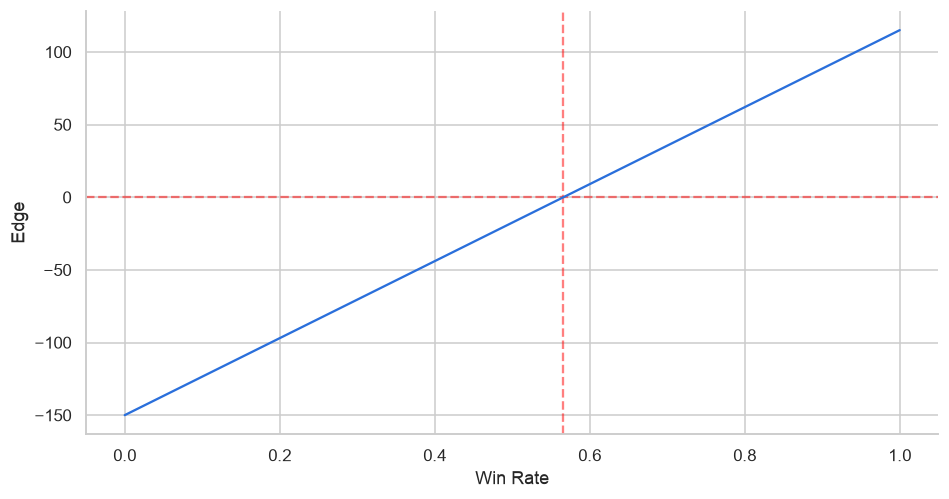

In [15]:
def edge(p_win, avg_win, avg_loss):
    edge_total_expectation = p_win * avg_win + (1 - p_win) * avg_loss
    return edge_total_expectation



def breakeven_p(avg_win, avg_loss):
    breakeven = -avg_loss / (avg_win - avg_loss)
    return breakeven

#Figures
win_rates = np.linspace(0, 1, 100)
edge_values = edge(win_rates, 115, -150)
plt.figure(figsize=(10, 5))
plt.xlabel("Win Rate")
plt.ylabel("Edge")
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.axvline(x=breakeven_p(115, -150), color='red', linestyle='--', alpha=0.5)
plt.plot(win_rates, edge_values)
plt.show()

In [16]:
check.task3_2(edge, breakeven_p)

✅ Task 3.2 edge() and breakeven_p(): breakeven win rate 56.6%: you need to win more than half to make money here


True

### Task 3.3
Assume the strategy truly wins 60% of the time, making +115 or −150 per trade (edge = +9). Simulate **1,000 years of 252 trades** and store the cumulative P/L paths in `curves` (shape `(1000, 252)`). Plot the paths (thin, transparent) plus their average.

**Predict first:** what fraction of years end in a loss, despite the positive edge? ➜ *my prediction:* the prob of ending a year in a loss is given by the probability of having a negative sum of 252 trades, which can be approximated by a normal distribution with mean = 252 * edge and variance of the sum = to the sum of variances of each trade, assuming independence. The variance of each trade can be computed as p*(avg_win - mean)^2 + (1-p)*(avg_loss - mean)^2, where mean is the expected value of the trade. The probability of winning here is 0.6 and the probability of losing is 0.4, so the variance of each trade is 0.6*(115 - 9)^2 + 0.4*(-150 - 9)^2 = 0.6*106^2 + 0.4*(-159)^2 = 0.6*11236 + 0.4*25281 = 6741.6 + 10112.4 = 16854, and the standard deviation of the sum of trades over a year is sqrt(252 * 16854) = sqrt(4247208) = 2061.5, and the mean of the sum is 252 * edge = 252 * 9 = 2268, so the probability of ending a year in a loss is P(X < 0) where X ~ N(2268, 2061.5^2), which can be computed as P(Z < (0 - 2268)/2061.5) = P(Z < -1.1) = 0.1357, so about 13.57% of years end in a loss. This assumes that the trades are independent and identically and normallu distributed, which may not be true in practice, but gives a rough estimate.

Store the simulated fraction in `prob_losing_year`. *Stretch:* derive it with the CLT (mean and variance of one trade, times 252).

In [74]:
curves = [np.cumsum([x for x in rng.choice([115, -150], size=252, p=[0.6, 0.4])]) for year in range(1000)]
# Simulate 1,000 years of 252 trades and store the cumulative P/L paths
prob_losing_year = np.mean([curve[-1] < 0 for curve in curves])  # store percentage of paths (simulated years) that end in a loss
print(f"The prob. of losing money over a year is: {prob_losing_year}")

The prob. of losing money over a year is: 0.135


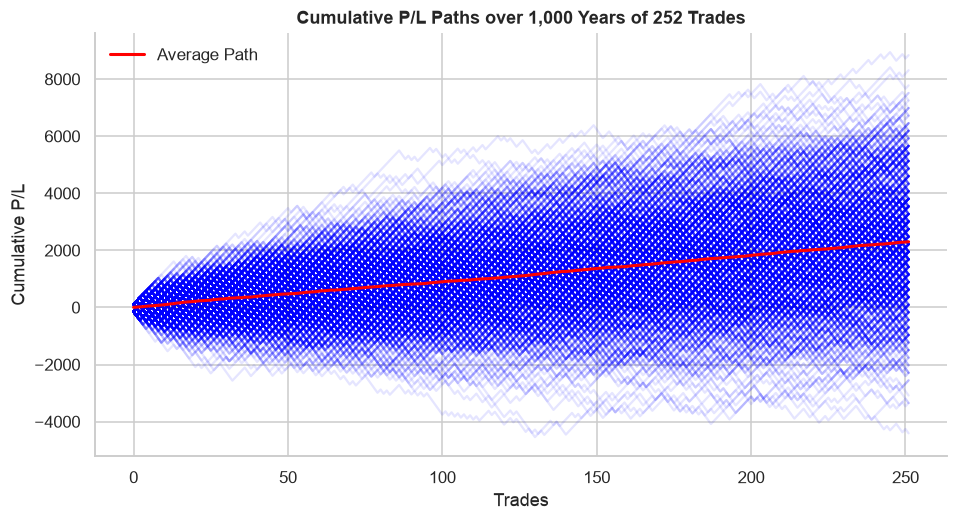

In [28]:
#Plotting the paths
plt.figure(figsize=(10, 5))
for curve in curves:
    plt.plot(curve, color='blue', alpha=0.1)
plt.plot(np.mean(curves, axis=0), color='red', lw=2, label='Average Path')
plt.xlabel("Trades")
plt.ylabel("Cumulative P/L")
plt.title("Cumulative P/L Paths over 1,000 Years of 252 Trades")
plt.legend()
plt.show()

In [75]:
check.task3_3(curves, prob_losing_year)

✅ Task 3.3 equity curves: ~14% of years lose money even with a genuine edge


True

### Task 3.4: back to the trader's 7 trades
We assumed $p = 0.6$, but the trader's win rate was estimated from **7 trades** (4 wins). Treat $p$ as unknown and use a flat prior. After 4 wins and 3 losses, the posterior for $p$ is $\text{Beta}(1+4,\ 1+3)$.

Compute `prob_profitable` $= P(p > \text{breakeven})$ under this posterior, using `stats.beta.cdf` and your `breakeven_p(115, -150)`. Plot the posterior density with the breakeven line.

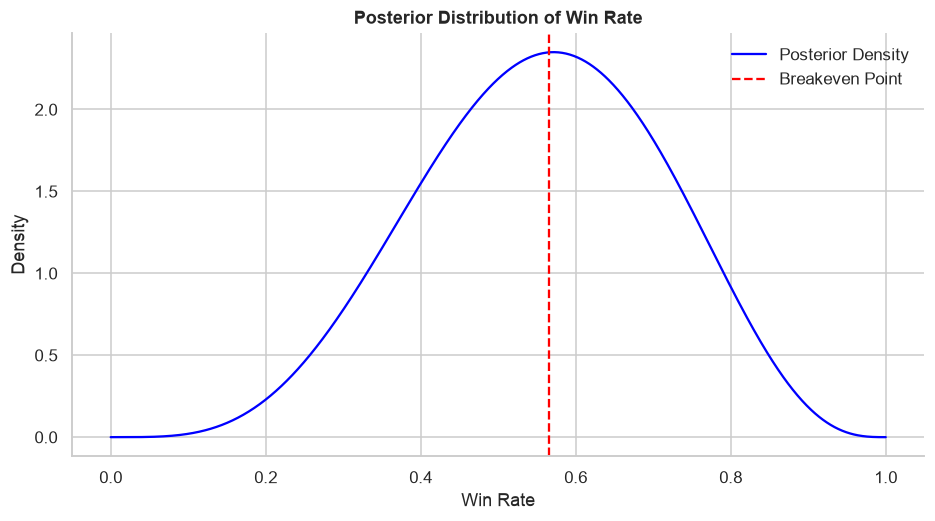

In [78]:
prob_profitable = 1 - stats.beta.cdf(breakeven_p(115, -150), 1+4, 1+3)

# plot posterior density and breakeven line
plt.figure(figsize=(10, 5))
x = np.linspace(0, 1, 1000)
posterior_density = stats.beta.pdf(x, 1+4, 1+3)
plt.plot(x, posterior_density, label='Posterior Density', color='blue')
plt.axvline(breakeven_p(115, -150), color='red', linestyle='--', label='Breakeven Point')
plt.xlabel('Win Rate')
plt.ylabel('Density')
plt.title('Posterior Distribution of Win Rate')
plt.legend()
plt.show()

In [79]:
check.task3_4(prob_profitable)

✅ Task 3.4 how sure can 7 trades make you?: P(strategy is profitable) ≈ 49%: about a coin toss


True

✍️ **Interpret:** so, does the trader have an edge? Answer the opening question in 3–4 sentences, using numbers from Parts 1 and 3.

*Your answer:* There is no way of knowing yet with statistical certainty. This is because the sample size is too small, making the distribution of the parameter estimate way too wide. The probability of the trader being profitable is only 0.49, which is not a strong enough signal to conclude that they have an edge. More trades are needed to reduce the uncertainty and make a more informed judgment.

## Part 4 · Real data: SPY's daily edge

Treat "buy SPY at the close, sell at the next close" as a trade made every day. Free data via `load_prices`.

### Task 4.1
Load SPY from 1993 (`load_prices("SPY", start="1993-01-01")`), compute daily **simple** returns `rets` (a Series with no NaNs), and decompose the edge: `p_win` (share of up days), `avg_win`, `avg_loss` (zero-return days count as losses), and `edge_bps` = edge × 10,000.

In [102]:
spy = load_prices("SPY", start="1993-01-01")
rets = load_prices("SPY", start="1993-01-01")["SPY"].pct_change().dropna()
p_win = np.mean(rets > 0)
avg_win = np.mean(rets[rets > 0])
avg_loss = np.mean(rets[rets <= 0])
edge_bps = (p_win * avg_win + (1 - p_win) * avg_loss) * 10000

In [103]:
check.task4_1(rets, p_win, edge_bps)

✅ Task 4.1 SPY edge decomposition: 54.0% up days, edge 4.76 bps/day


True

### Task 4.2
Is SPY's edge distinguishable from zero? Build a **bootstrap** 95% confidence interval for the mean daily return: resample `rets` with replacement 5,000 times (same length each time), take the mean of each resample, and read off the 2.5% and 97.5% percentiles. Store them **in bps** as `ci_low` and `ci_high`. Plot the bootstrap distribution with the interval and zero marked.

*Compare:* the t-statistic, mean / (sd / √n). Do the two approaches agree?

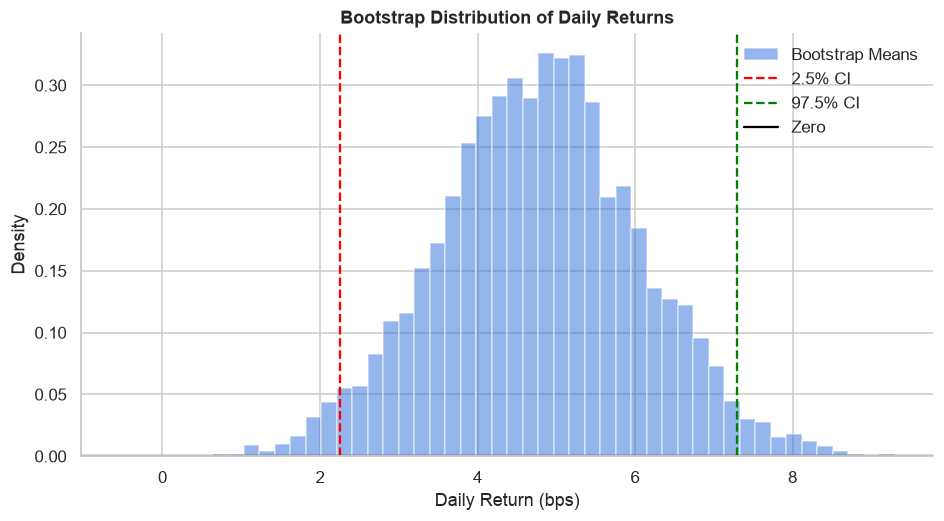

In [110]:

means = np.zeros(5000)
for i in range(5000): #for each bootstrap sample
    sample = rets.sample(len(rets), replace=True)
    means[i] = sample.mean() #compute mean of the sample


ci_low, ci_high = np.percentile(means, [2.5, 97.5]) * 10000  # convert to bps
# Plotting the bootstrap distribution
plt.figure(figsize=(10, 5))
plt.hist(means * 10000, bins=50, density=True, alpha=0.5, label='Bootstrap Means')
plt.axvline(ci_low, color='red', linestyle='--', label='2.5% CI')
plt.axvline(ci_high, color='green', linestyle='--', label='97.5% CI')
plt.axhline(0, color='black', linestyle='-', label='Zero')
plt.xlabel('Daily Return (bps)')
plt.ylabel('Density')
plt.title('Bootstrap Distribution of Daily Returns')
plt.legend()
plt.show()



In [109]:
check.task4_2(ci_low, ci_high, rets)

✅ Task 4.2 bootstrap CI: 95% CI [2.22, 7.16] bps/day


True

### Task 4.3: is SPY's win rate stationary? (no checkpoint, your judgement)
Compute the win rate **by calendar year** (`rets.groupby(rets.index.year)`). Plot it with a ±1.96 × standard-error band around the overall average, where se $= \sqrt{\bar p(1-\bar p)/n_{\text{days}}}$. If the win rate were constant, about 95% of years would fall inside the band. How many do? Which years fall outside, and what happened in markets those years?

The overall average win rate is: 0.539842039449329
Standard errors by year: Date
1993    0.032732
1994    0.031496
1995    0.031056
1996    0.031310
1997    0.031281
1998    0.031472
1999    0.031493
2000    0.031481
2001    0.031749
2002    0.031461
2003    0.031242
2004    0.031242
2005    0.031377
2006    0.031318
2007    0.031403
2008    0.031434
2009    0.031273
2010    0.031098
2011    0.031398
2012    0.031477
2013    0.031098
2014    0.030968
2015    0.031472
2016    0.031377
2017    0.031251
2018    0.031503
2019    0.030920
2020    0.031059
2021    0.031098
2022    0.031286
2023    0.031394
2024    0.031013
2025    0.031293
2026    0.035440
Name: SPY, dtype: float64


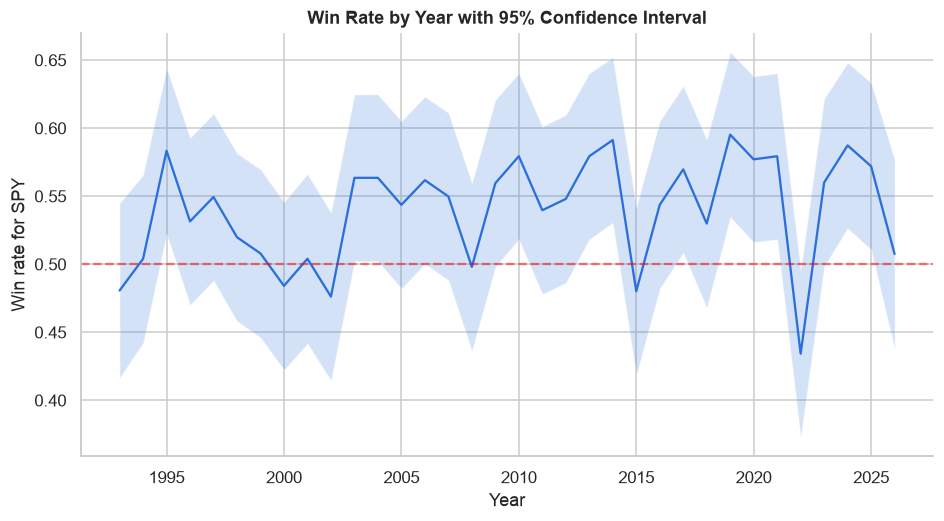

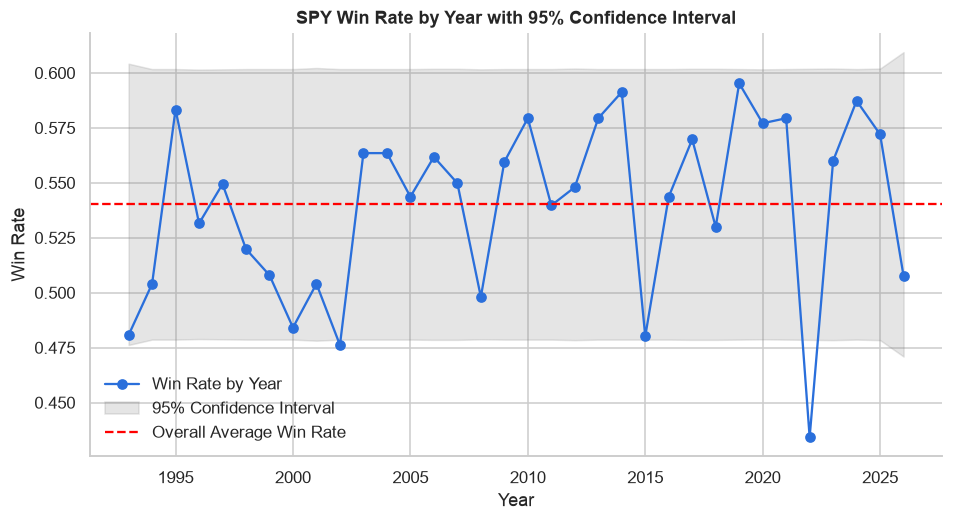

Years outside the 95% confidence interval: [2002, 2022]


In [129]:
rets_by_year = rets.groupby(rets.index.year)
win_rate_by_year = rets_by_year.apply(lambda x: np.mean(x > 0))
print(f"The overall average win rate is: {np.mean(win_rate_by_year)}")

# Calculate standard error for each year
se_by_year = rets_by_year.apply(lambda x: np.sqrt(np.mean(x > 0) * (1 - np.mean(x > 0)) / len(x)))
print(f"Standard errors by year: {se_by_year}")
ci_upper_by_year = win_rate_by_year + 1.96 * se_by_year
ci_lower_by_year = win_rate_by_year - 1.96 * se_by_year

#Plotting
plt.figure(figsize=(10, 5))
plt.plot(win_rate_by_year)
plt.fill_between(ci_upper_by_year.index, ci_lower_by_year, ci_upper_by_year, alpha=0.2)
plt.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Year')
plt.ylabel('Win rate for SPY')
plt.title('Win Rate by Year with 95% Confidence Interval')
plt.show()

se = np.sqrt(np.mean(rets>0) * (1 - np.mean(rets>0)) / rets_by_year.size())
ci_upper = np.mean(rets>0) + 1.96 * se
ci_lower = np.mean(rets>0) - 1.96 * se
years_outside = win_rate_by_year[(win_rate_by_year < ci_lower) | (win_rate_by_year > ci_upper)].index.tolist()

#Plotting the win rate by year with confidence intervals
plt.figure(figsize=(10, 5))
plt.plot(win_rate_by_year, marker='o', label='Win Rate by Year')
plt.fill_between(win_rate_by_year.index, ci_lower, ci_upper, color='gray', alpha=0.2, label='95% Confidence Interval')
plt.axhline(y=np.mean(rets>0), color='red', linestyle='--', label='Overall Average Win Rate')
plt.xlabel('Year')
plt.ylabel('Win Rate')
plt.title('SPY Win Rate by Year with 95% Confidence Interval')
plt.legend()
plt.show()
print(f"Years outside the 95% confidence interval: {years_outside}")

✍️ **Interpret:**

*Your answer:* I would say that the win rate is mostly stationary, but there are a couple of exceptions, namely 2002 and 2022, years of recessions.

## Part 5 · Your extension

Pick **one** (or invent your own) and give it a heading, code, a chart and an interpretation:

1. **FX:** repeat Part 4 on `EURUSD=X` (or a pair from your research). Is there any edge in a long-only FX position?
2. **A real strategy:** long SPY only when it closes above its 200-day moving average. Decompose that strategy's edge and bootstrap it. Is it better than buy-and-hold *per day invested*?
3. **Interactive:** recreate the lecture's sliders with `ipywidgets.interact`: win rate, average win and average loss drive a live equity-curve fan.
4. **Non-stationary edge:** use a rolling 1-year window for SPY's edge (in bps) with bootstrap bands. When was the edge reliably positive?

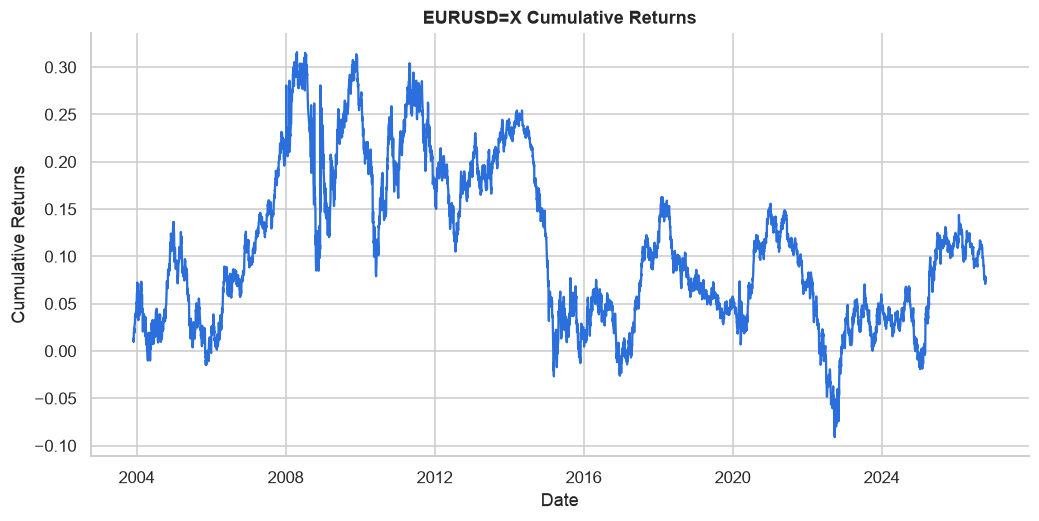

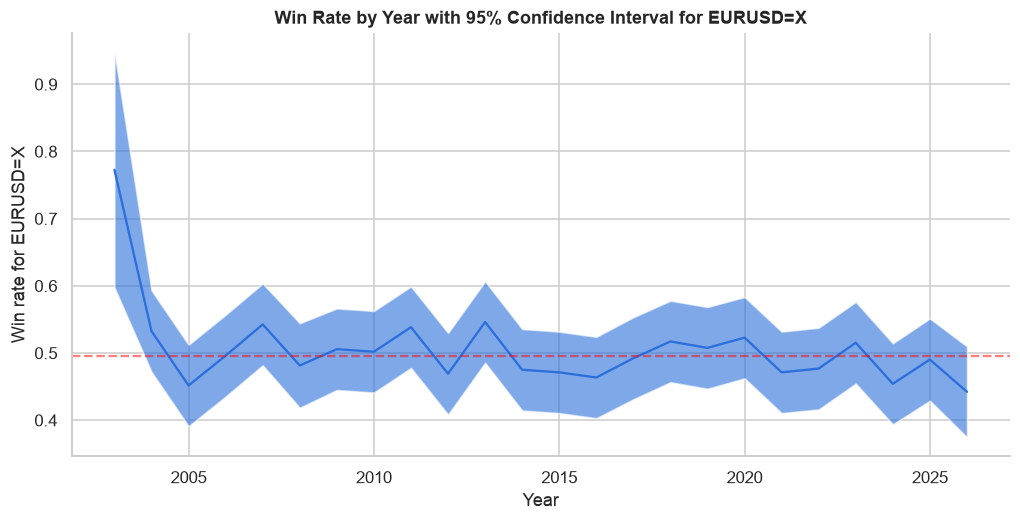

In [138]:
# Extension
eurusd = load_prices("EURUSD=X", start="1993-01-01")
rets_eurusd = eurusd["EURUSD=X"].pct_change().dropna()
p_win_eurusd = np.mean(rets_eurusd > 0)
avg_win_eurusd = np.mean(rets_eurusd[rets_eurusd > 0])
avg_loss_eurusd = np.mean(rets_eurusd[rets_eurusd <= 0])
edge_bps_eurusd = (p_win_eurusd * avg_win_eurusd + (1 - p_win_eurusd) * avg_loss_eurusd) * 10000

plt.plot(np.cumsum(rets_eurusd))
plt.title('EURUSD=X Cumulative Returns')
plt.xlabel('Date')
plt.ylabel('Cumulative Returns')
plt.show()

eur_rets_by_year = rets_eurusd.groupby(rets_eurusd.index.year)
win_rate_by_year = eur_rets_by_year.apply(lambda x: np.mean(x > 0))
se_by_year = eur_rets_by_year.apply(lambda x: np.sqrt(np.mean(x > 0) * (1 - np.mean(x > 0)) / len(x)))
ci_lower_by_year = win_rate_by_year - 1.96 * se_by_year
ci_upper_by_year = win_rate_by_year + 1.96 * se_by_year

#Plotting the win rate by year with confidence intervals for EURUSD
plt.plot(win_rate_by_year)
plt.fill_between(win_rate_by_year.index, ci_upper_by_year, ci_lower_by_year, alpha=0.6)
plt.axhline(y=np.mean(rets_eurusd > 0), color='red', linestyle='--', alpha=0.5)
plt.xlabel('Year')
plt.ylabel('Win rate for EURUSD=X')
plt.title('Win Rate by Year with 95% Confidence Interval for EURUSD=X')
plt.show()


## Takeaways *(write 3–5 in your own words)*

1. The win rate for spy is generally stationary, but there are a few years where it is not, which can be attributed to recessions or other market events.
2. The win rate for eurusd is also generally stationary, but there are a few years where it is not, which can be attributed to recessions or other market events.
3.

## Recall questions for tomorrow
Write three questions you should be able to answer from memory (they go in `study/LEARNING_LOG.md` too):

1.How do you compute the standard error of a win rate estimate, and how does it change with sample size?
2.How does the law of total variance explain the effect of non-stationarity on the standard error of an estimate?
3.How do you compute the expected P/L per trade given win rate, average win, and average loss, and how do you find the breakeven win rate?